In [201]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pandas.api.types import is_string_dtype,is_integer_dtype,is_float_dtype
import yaml

In [202]:
with open("../configure.yaml", "r") as f:
    config = yaml.safe_load(f)
    
target=config["target"]

In [203]:
dataframe = []

for rutas in range(0, 4):
    ruta = f"../data/bronze/train{rutas}.parquet"
    parque = pd.read_parquet(ruta)
    dataframe.append(parque)

df = pd.concat(dataframe, ignore_index=True)

df

,id,date,store_nbr,family,sales,onpromotion
0,1367,2013-01-01,47,HARDWARE,0.000,0
1,0,2013-01-01,1,AUTOMOTIVE,0.000,0
2,1,2013-01-01,1,BABY CARE,0.000,0
3,2,2013-01-01,1,BEAUTY,0.000,0
4,3,2013-01-01,1,BEVERAGES,0.000,0
...,...,...,...,...,...,...
3000883,3000794,2017-08-15,7,BREAD/BAKERY,659.156,11
3000884,3000795,2017-08-15,7,CELEBRATION,11.000,0
3000885,3000796,2017-08-15,7,CLEANING,1139.000,9
3000886,3000797,2017-08-15,7,DAIRY,1279.000,25


In [204]:
df.shape

(3000888, 6)

In [205]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype  
---  ------       -----  
 0   id           int64  
 1   date         str    
 2   store_nbr    int64  
 3   family       str    
 4   sales        float64
 5   onpromotion  int64  
dtypes: float64(1), int64(3), str(2)
memory usage: 196.8 MB


### MEMORIA

In [206]:
def memoria(df):
    df["date"]=pd.to_datetime(df["date"])
    for col in df.columns:
        if is_string_dtype(df[col]):
            df[col]=df[col].astype("category")

        elif is_float_dtype(df[col]):
            df[col]=pd.to_numeric(df[col],downcast="float")

        elif is_integer_dtype(df[col]):
            df[col]=pd.to_numeric(df[col],downcast="integer")
    
    return df

df=memoria(df)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype         
---  ------       -----         
 0   id           int32         
 1   date         datetime64[us]
 2   store_nbr    int8          
 3   family       category      
 4   sales        float64       
 5   onpromotion  int16         
dtypes: category(1), datetime64[us](1), float64(1), int16(1), int32(1), int8(1)
memory usage: 68.7 MB


In [207]:
df.isnull().sum()

id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64

In [208]:
df.duplicated().sum()

np.int64(0)

### CORRELACION

<Axes: >

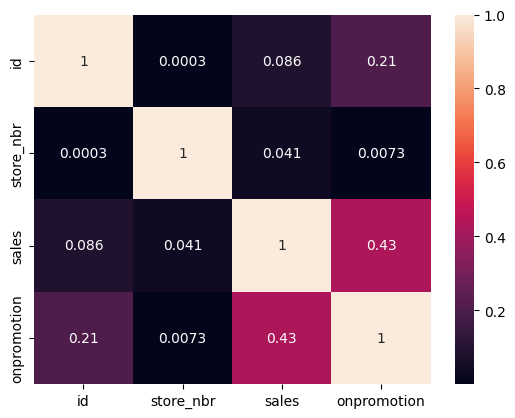

In [209]:
col_number=df.select_dtypes(include="number").columns
col_category=df.select_dtypes(include="category").columns

sns.heatmap(df[col_number].corr(),annot=True)

In [210]:
df.select_dtypes(include="number").corr()[target].sort_values(ascending=False)

sales          1.000000
onpromotion    0.427923
id             0.085784
store_nbr      0.041196
Name: sales, dtype: float64

In [211]:
def inportancia():
    resultado=[]
    for col in col_category:
        top=df.groupby(col)[target].mean()
        diff=top.max()-top.min()
        resultado.append((col,diff))
    res=pd.DataFrame(resultado,columns=["category","diff"])
    res.sort_values(by="diff",ascending=False)
    return res

inportancia()

,category,diff
0,family,3776.901303


In [212]:
df.drop(columns=["id","store_nbr"],inplace=True)

### OUTLIERS

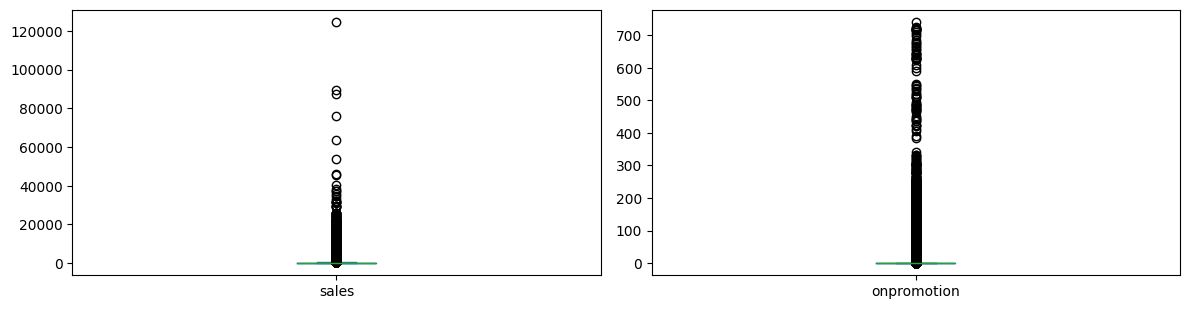

In [213]:
df.plot(kind="box",subplots=True,layout=(2,2),figsize=(12,6),sharex=False,sharey=False)
plt.tight_layout()
plt.show()

## EDA PROFUNDO

### SALES

In [214]:
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
import numpy as np

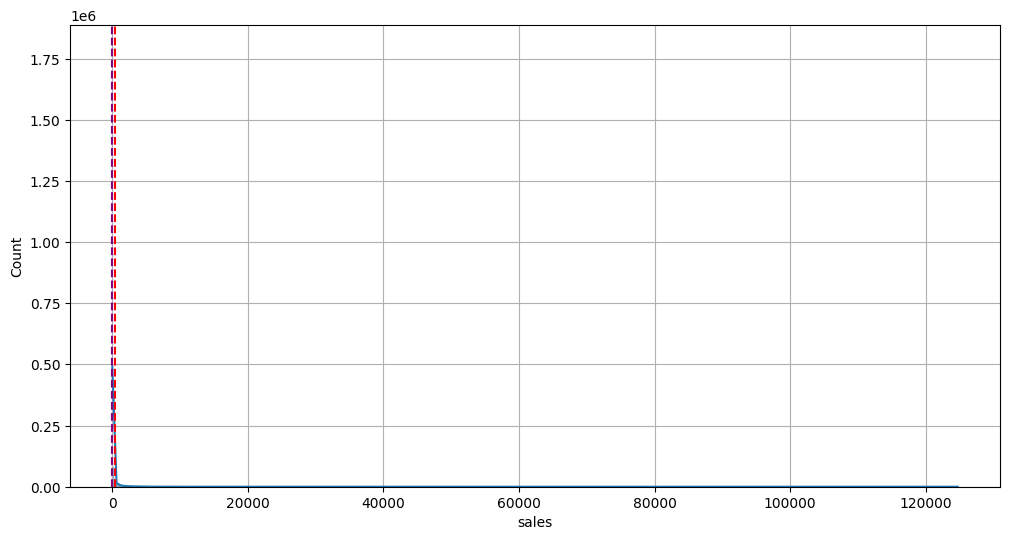

In [215]:
plt.figure(figsize=(12,6))
sns.histplot(data=df,x=target,kde=True)
plt.axvline(df[target].mean(),label="Promedio",ls="--",color="red")
plt.axvline(df[target].median(),label="Median",ls="--",color="purple")
plt.grid()
plt.show()

In [216]:
print(f"Promedio de sales: {df[target].mean():.2f}")
print(f"Median de sales: {df[target].median():.2f}")

Promedio de sales: 357.78
Median de sales: 11.00


In [217]:
print(f"Curtosis: {df[target].kurt():.2f}")
print(f"Asimetria: {df[target].skew():.2f}")

Curtosis: 154.56
Asimetria: 7.36


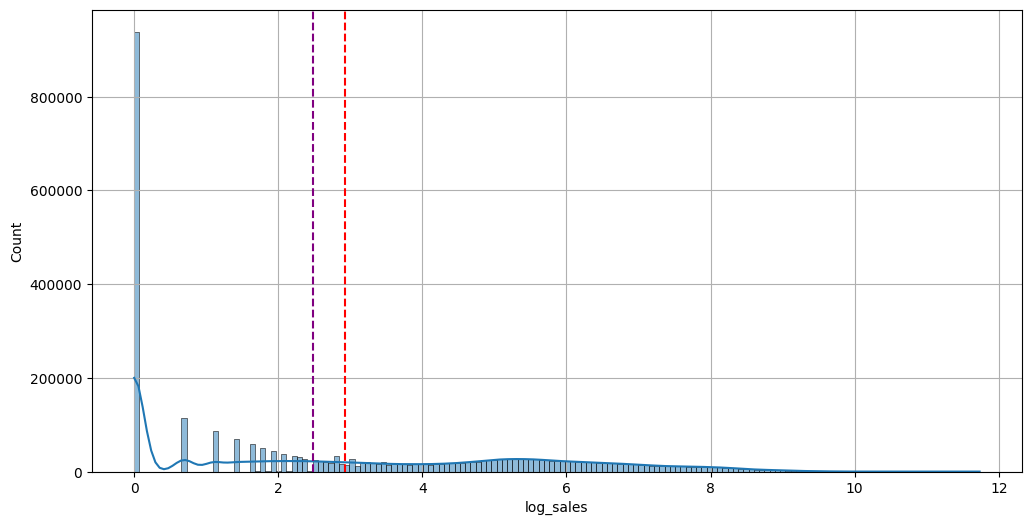

In [218]:
df["log_sales"]=np.log1p(df[target])
plt.figure(figsize=(12,6))
sns.histplot(data=df,x="log_sales",kde=True)
plt.axvline(df["log_sales"].mean(),label="Promedio",ls="--",color="red")
plt.axvline(df["log_sales"].median(),label="Median",ls="--",color="purple")
plt.grid()
plt.show()

In [219]:
print(f"Promedio de log_sales: {df["log_sales"].mean():.2f}")
print(f"Median de log_sales: {df["log_sales"].median():.2f}")

Promedio de log_sales: 2.93
Median de log_sales: 2.48


In [220]:
print(f"Curtosis: {df["log_sales"].kurt():.2f}")
print(f"Asimetria: {df["log_sales"].skew():.2f}")

Curtosis: -1.15
Asimetria: 0.41


In [221]:
df.set_index("date",inplace=True)

In [222]:
monthly = (df
      .resample("ME")[target]
      .sum()
      .to_frame()
)

monthly["log_sales"] = np.log1p(monthly[target])

monthly["Rolling"] = (
    monthly["log_sales"]
    .rolling(window=3)
    .mean()
)

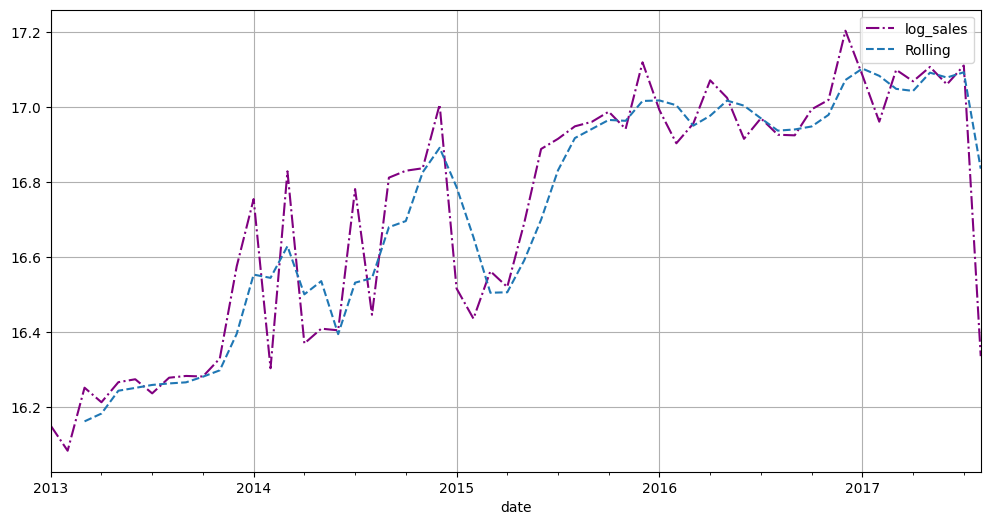

In [223]:
ax=monthly["log_sales"].plot(figsize=(12,6),ls="-.",color="purple")
monthly["Rolling"].plot(ax=ax,ls="--")
plt.legend()
plt.grid()
plt.show()

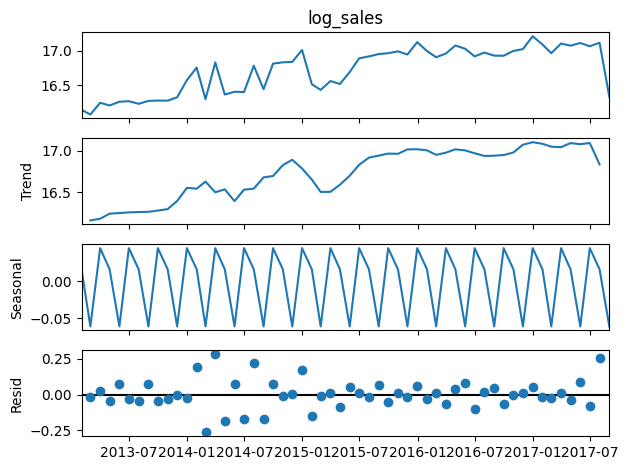

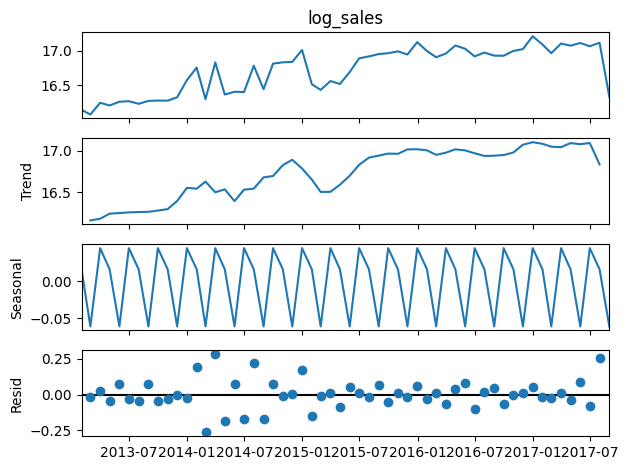

In [224]:
seasonal_decompose(monthly["log_sales"],model="additive",period=3).plot()

In [225]:
resultado=adfuller(monthly["log_sales"].dropna())
print("ADF Statistic:", resultado[0])
print("p-value:", resultado[1])

ADF Statistic: -2.1855249908641845
p-value: 0.21154093237532584


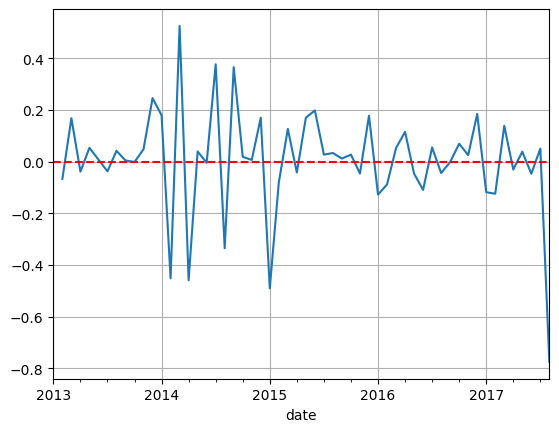

In [226]:
monthly["diff_sales"]=monthly["log_sales"].diff()
monthly["diff_sales"].plot()
plt.axhline(0,color="red",ls="--")
plt.grid()

In [227]:
monthly.drop(columns=["sales","Rolling"],inplace=True)

In [228]:
monthly
monthly_2=monthly.drop(columns="diff_sales").copy()

### ONPROMOTION

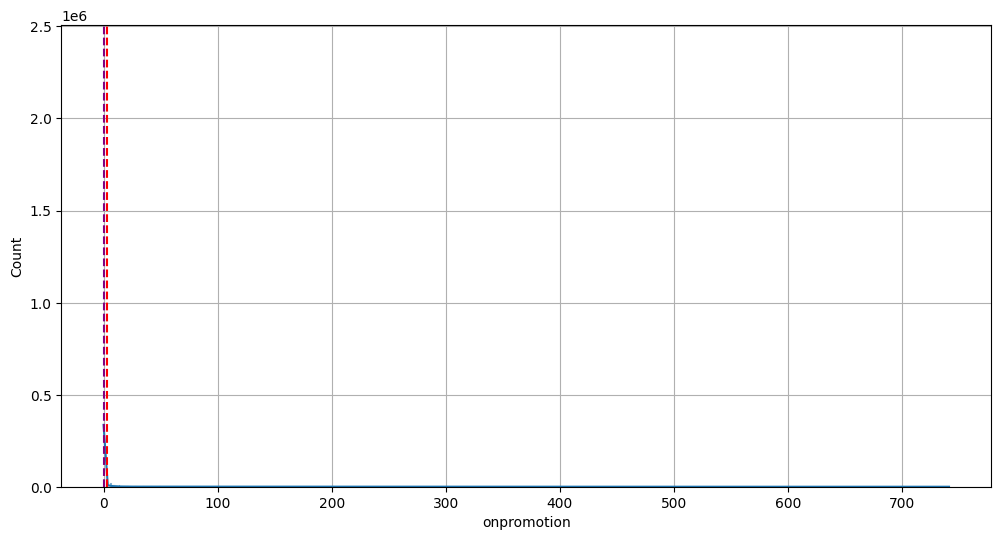

In [229]:
plt.figure(figsize=(12,6))
sns.histplot(data=df,x="onpromotion",kde=True)
plt.axvline(df["onpromotion"].mean(),label="Promedio",ls="--",color="red")
plt.axvline(df["onpromotion"].median(),label="Median",ls="--",color="purple")
plt.grid()
plt.show()

In [230]:
print(f"Promedio de Onpromotion: {df["onpromotion"].mean():.2f}")
print(f"Median de Onpromotion: {df["onpromotion"].median():.2f}")

Promedio de Onpromotion: 2.60
Median de Onpromotion: 0.00


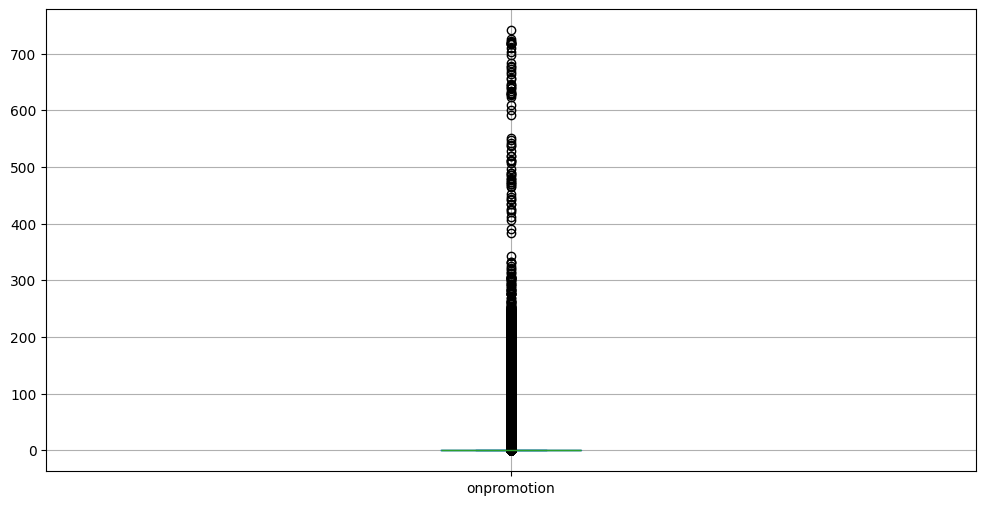

In [231]:
df["onpromotion"].plot(kind="box",subplots=True,figsize=(12,6),sharex=False,sharey=False)
plt.grid()

In [232]:
from scipy.stats import zscore

z=zscore(df["onpromotion"])
outliers=df[np.abs(z)>5]
outliers.loc[outliers["onpromotion"]>200]

,family,sales,onpromotion,log_sales
date,,,,
2014-11-05,PRODUCE,8873.863,201,9.090978
2014-11-26,PRODUCE,8249.161,201,9.017988
2014-12-17,PRODUCE,9164.784,201,9.123233
2014-12-17,PRODUCE,6548.899,205,8.787205
2014-12-24,PRODUCE,8180.103,201,9.009582
...,...,...,...,...
2017-08-09,PRODUCE,9147.198,243,9.121312
2017-08-09,PRODUCE,6733.922,223,8.815062
2017-08-09,PRODUCE,2940.584,214,7.986703


## FEATURES

<Axes: >

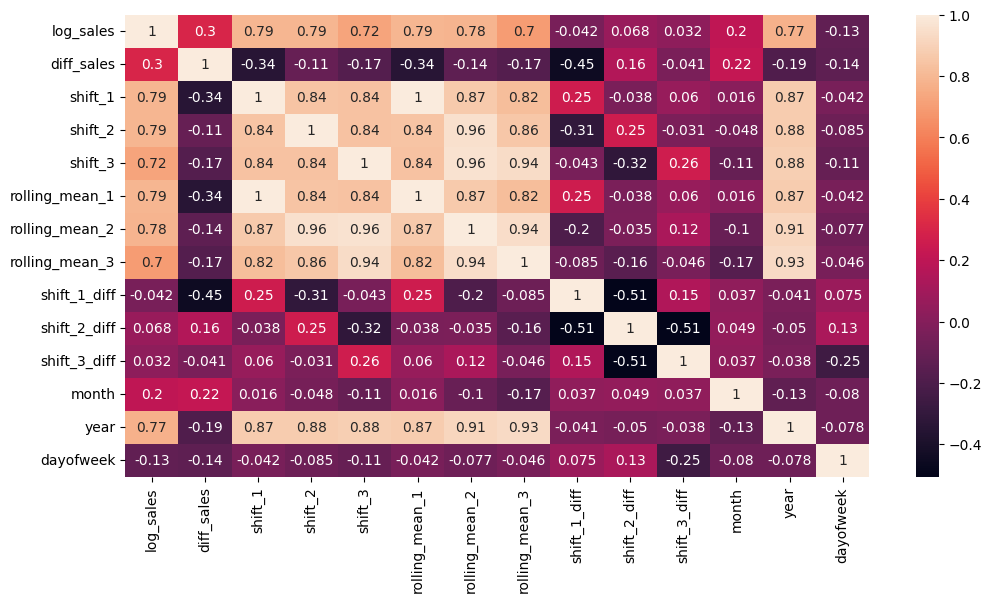

In [233]:
def features():
    monthly["shift_1"]=monthly["log_sales"].shift(1)
    monthly["shift_2"]=monthly["log_sales"].shift(2)
    monthly["shift_3"]=monthly["log_sales"].shift(3)
    monthly["rolling_mean_1"]=monthly["log_sales"].shift(1).rolling(1).mean()
    monthly["rolling_mean_2"]=monthly["log_sales"].shift(2).rolling(2).mean()    
    monthly["rolling_mean_3"]=monthly["log_sales"].shift(3).rolling(3).mean()
    monthly["shift_1_diff"]=monthly["diff_sales"].shift(1)
    monthly["shift_2_diff"]=monthly["diff_sales"].shift(2)
    monthly["shift_3_diff"]=monthly["diff_sales"].shift(3)
    monthly["month"]=monthly.index.month
    monthly["year"]=monthly.index.year
    monthly["dayofweek"]=monthly.index.dayofweek
    return monthly

monthly = features()

plt.figure(figsize=(12,6))
sns.heatmap(monthly.select_dtypes(include="number").corr(),annot=True)

In [234]:
monthly.select_dtypes(include="number").corr()["log_sales"].sort_values(ascending=False)

log_sales         1.000000
shift_1           0.791975
rolling_mean_1    0.791975
shift_2           0.788377
rolling_mean_2    0.782346
year              0.772461
shift_3           0.723664
rolling_mean_3    0.698346
diff_sales        0.300532
month             0.199914
shift_2_diff      0.068132
shift_3_diff      0.032047
shift_1_diff     -0.042262
dayofweek        -0.127222
Name: log_sales, dtype: float64

## GUARDAR

In [235]:
monthly.to_parquet("../data/silver/monthly.parquet")
monthly_2.to_parquet("../data/silver/monthly_2.parquet")
df.to_csv("../data/silver/df.csv",index=False)